In [3]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
import sklearn

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/credit-screening/crx.data"

data = pd.read_csv(url, header=None)   # Tells pandas that the first row contains actual data, not column headings


Dataset loaded successfully!


In [7]:
data.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
0,b,30.83,0.000,u,g,w,v,1.25,t,t,1,f,g,00202,0,+
1,a,58.67,4.460,u,g,q,h,3.04,t,t,6,f,g,00043,560,+
2,a,24.50,0.500,u,g,q,h,1.50,t,f,0,f,g,00280,824,+
3,b,27.83,1.540,u,g,w,v,3.75,t,t,5,t,g,00100,3,+
4,b,20.17,5.625,u,g,w,v,1.71,t,f,0,f,s,00120,0,+


In [5]:
data.shape

(690, 16)

In [8]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 690 entries, 0 to 689
Data columns (total 16 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       690 non-null    str    
 1   1       690 non-null    str    
 2   2       690 non-null    float64
 3   3       690 non-null    str    
 4   4       690 non-null    str    
 5   5       690 non-null    str    
 6   6       690 non-null    str    
 7   7       690 non-null    float64
 8   8       690 non-null    str    
 9   9       690 non-null    str    
 10  10      690 non-null    int64  
 11  11      690 non-null    str    
 12  12      690 non-null    str    
 13  13      690 non-null    str    
 14  14      690 non-null    int64  
 15  15      690 non-null    str    
dtypes: float64(2), int64(2), str(12)
memory usage: 86.4 KB


In [12]:
data.isnull().sum()


0     0
1     0
2     0
3     0
4     0
5     0
6     0
7     0
8     0
9     0
10    0
11    0
12    0
13    0
14    0
15    0
dtype: int64

In [11]:
(data == "?").sum()   # checks every cell to see whether its value is ?

0     12
1     12
2      0
3      6
4      6
5      9
6      9
7      0
8      0
9      0
10     0
11     0
12     0
13    13
14     0
15     0
dtype: int64

In [13]:
for col in data.columns:       # iterates through every column
    if (data[col] == "?").any():   # checks whether a column contains at least one question mark
        print(f"Column {col}: {data[col].unique()}")   # displays the distinct values in that column

Column 0: <StringArray>
['b', 'a', '?']
Length: 3, dtype: str
Column 1: <StringArray>
['30.83', '58.67', '24.50', '27.83', '20.17', '32.08', '33.17', '22.92',
 '54.42', '42.50',
 ...
 '38.75', '35.58', '31.58', '15.75', '17.92', '30.33', '47.17', '25.83',
 '50.25', '36.42']
Length: 350, dtype: str
Column 3: <StringArray>
['u', 'y', '?', 'l']
Length: 4, dtype: str
Column 4: <StringArray>
['g', 'p', '?', 'gg']
Length: 4, dtype: str
Column 5: <StringArray>
['w', 'q', 'm', 'r', 'cc', 'k', 'c', 'd', 'x', 'i', 'e', 'aa', 'ff', 'j', '?']
Length: 15, dtype: str
Column 6: <StringArray>
['v', 'h', 'bb', 'ff', 'j', 'z', '?', 'o', 'dd', 'n']
Length: 10, dtype: str
Column 13: <StringArray>
['00202', '00043', '00280', '00100', '00120', '00360', '00164', '00080',
 '00180', '00052',
 ...
 '00303', '00349', '00224', '00369', '00076', '00231', '00309', '00416',
 '00465', '00256']
Length: 171, dtype: str


In [ ]:
data = data.replace('?', np.nan)   # replaces every ? with Numpy's standard missing-value marker, np.nan
data.isnull().sum()           # counts the missing values in each column

0     12
1     12
2      0
3      6
4      6
5      9
6      9
7      0
8      0
9      0
10     0
11     0
12     0
13    13
14     0
15     0
dtype: int64

In [16]:
data.isnull().any(axis=1).sum()    # isnull() identifies missing cells, any(axis=1) checks whether each row has at least one missing values, sum() conts the rows where that condition is true

np.int64(37)

In [ ]:
data.describe()     # generates statistical summaries of numerical columns

,2,7,10,14
count,690.000000,690.000000,690.00000,690.000000
mean,4.758725,2.223406,2.40000,1017.385507
std,4.978163,3.346513,4.86294,5210.102598
min,0.000000,0.000000,0.00000,0.000000
25%,1.000000,0.165000,0.00000,0.000000
50%,2.750000,1.000000,0.00000,5.000000
75%,7.207500,2.625000,3.00000,395.500000
max,28.000000,28.500000,67.00000,100000.000000


In [18]:
data[14].sort_values(ascending=False).head(10)  # data[14] selects column 14, sort_values arranges its values, ascending =false sorts from largest to smallest, head(10) displays the ten largest values

317    100000
132     51100
65      50000
6       31285
243     26726
245     18027
67      15108
180     15000
584     13212
117     11202
Name: 14, dtype: int64

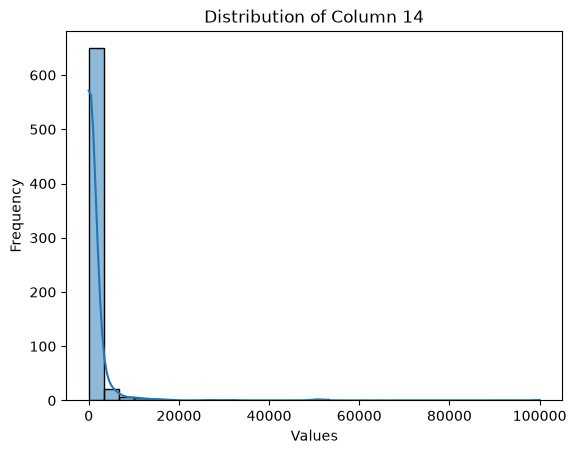

In [19]:
sns.histplot(data[14], bins=30, kde=True)  # sns.histplot() creates a histogram, data[14] selects the column, bins=30 divides the value into 30 intervals kde=True adds a smooth distribution curve
plt.title("Distribution of Column 14")  # Gives the chart a title
plt.xlabel("Values") # label the axis
plt.ylabel("Frequency")  # label the axis
plt.show()  # displays the chart
